In [1]:
import pandas as pd
from pathlib import Path

RAIZ = Path.cwd().parent
precios = pd.read_parquet(RAIZ / "data" / "prices.parquet")
retornos = precios.pct_change().dropna()

print("Precios:", precios.shape)
print("Retornos:", retornos.shape)
retornos.tail()

Precios: (4959, 14)
Retornos: (4958, 14)


Ticker,EEM,EFA,GLD,IEF,TLT,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,,,,
2026-09-14,-0.027270,-0.007966,-0.014871,-0.000879,0.000742,-0.009028,-0.009364,-0.003843,-0.014156,-0.018064,0.012473,-0.013447,0.014453,-0.000974
2026-09-15,-0.003485,-0.004251,0.003335,-0.001210,-0.002718,0.004753,0.021695,-0.003156,-0.006355,-0.002930,-0.008173,-0.011956,-0.000536,-0.017457
2026-09-16,-0.000608,-0.003605,-0.006114,-0.000991,0.002106,-0.007293,-0.028818,-0.016183,-0.000829,0.001034,-0.004777,0.000000,0.000656,-0.006313
2026-09-17,0.018107,0.009712,0.016899,0.005731,0.011128,0.006950,0.007028,-0.000894,0.001778,0.022454,0.001920,0.008954,0.006199,0.010982
2026-09-18,0.001793,-0.010091,0.007054,-0.004931,-0.006481,-0.014198,-0.002637,-0.000358,0.004378,0.008189,-0.008264,-0.014152,-0.002488,-0.003232


In [2]:
print("Valores faltantes por activo:")
print(retornos.isna().sum().to_string())
print()

resumen = pd.DataFrame({
    "media_anual_%": retornos.mean() * 252 * 100,
    "vol_anual_%": retornos.std() * (252 ** 0.5) * 100,
    "peor_dia_%": retornos.min() * 100,
    "mejor_dia_%": retornos.max() * 100,
})
resumen.round(2).sort_values("vol_anual_%")

Valores faltantes por activo:
Ticker
EEM    0
EFA    0
GLD    0
IEF    0
TLT    0
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0



,media_anual_%,vol_anual_%,peor_dia_%,mejor_dia_%
Ticker,,,,
IEF,3.28,6.92,-2.51,3.43
XLP,9.53,14.56,-9.40,8.51
TLT,3.80,15.02,-6.67,7.52
XLV,11.40,17.19,-9.86,12.05
GLD,11.13,18.18,-10.27,11.29
XLU,9.32,19.07,-11.36,12.79
XLI,12.20,21.48,-11.34,12.65
EFA,7.10,21.59,-11.16,15.89
XLY,12.73,22.66,-12.67,10.89


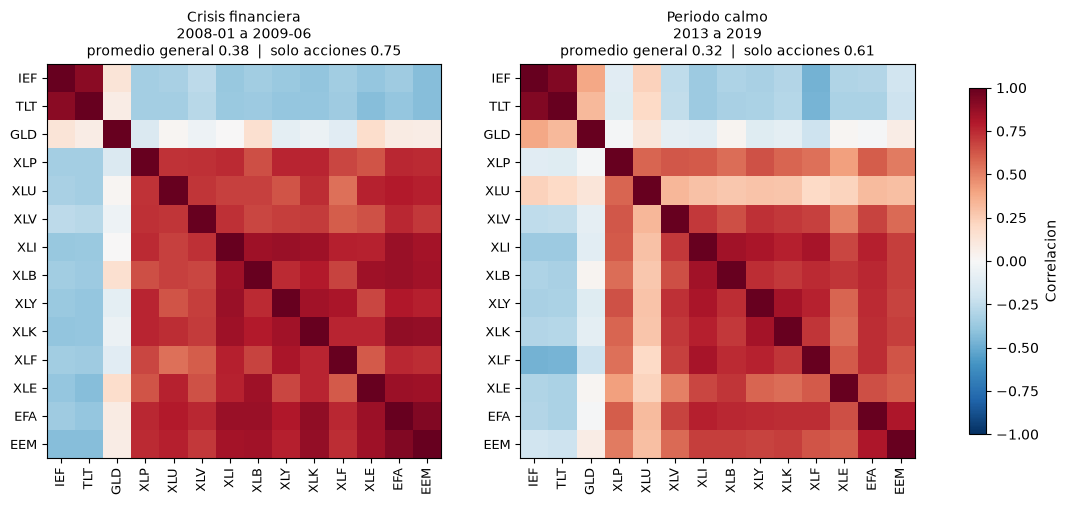

Solo acciones, crisis: 0.754
Solo acciones, calma:  0.609


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Agrupados por clase de activo, no alfabeticamente:
# la estructura de bloques solo se ve si el orden tiene sentido economico
ORDEN = [
    "IEF", "TLT",                                    # renta fija
    "GLD",                                           # oro
    "XLP", "XLU", "XLV",                             # sectores defensivos
    "XLI", "XLB", "XLY", "XLK", "XLF", "XLE",        # sectores ciclicos
    "EFA", "EEM",                                    # acciones internacionales
]
ACCIONES = ORDEN[3:]   # todo menos IEF, TLT y GLD

crisis = retornos.loc["2008-01-01":"2009-06-30", ORDEN].corr()
calma  = retornos.loc["2013-01-01":"2019-12-31", ORDEN].corr()


def corr_promedio(matriz, activos=None):
    """Promedio de las correlaciones fuera de la diagonal."""
    m = matriz if activos is None else matriz.loc[activos, activos]
    fuera_diagonal = m.values[np.triu_indices_from(m.values, k=1)]
    return fuera_diagonal.mean()


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, m, titulo in zip(
    axes,
    [crisis, calma],
    ["Crisis financiera\n2008-01 a 2009-06", "Periodo calmo\n2013 a 2019"],
):
    im = ax.imshow(m, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(ORDEN)))
    ax.set_xticklabels(ORDEN, rotation=90, fontsize=9)
    ax.set_yticks(range(len(ORDEN)))
    ax.set_yticklabels(ORDEN, fontsize=9)
    ax.set_title(
        f"{titulo}\npromedio general {corr_promedio(m):.2f}"
        f"  |  solo acciones {corr_promedio(m, ACCIONES):.2f}",
        fontsize=10,
    )

fig.colorbar(im, ax=axes, shrink=0.75, label="Correlacion")

RESULTADOS = RAIZ / "results"
RESULTADOS.mkdir(exist_ok=True)
plt.savefig(RESULTADOS / "correlaciones_regimen.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Solo acciones, crisis: {corr_promedio(crisis, ACCIONES):.3f}")
print(f"Solo acciones, calma:  {corr_promedio(calma, ACCIONES):.3f}")